<a href="https://colab.research.google.com/github/hugoweberlorton-boop/fx-hedging-model/blob/main/FX_Hedging_USD_EUR_CNY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FX Hedging of a USD Receivable: a French Exporter vs a Chinese Exporter

**Author:** Hugo Weber Lorton - MSc International Finance (Financial Markets & Risk Management), NEOMA Business School

## The situation
Most international trade is invoiced in **US dollars**, including most of China's exports.
I compare two exporters that both **receive USD 10M in 6 months** but keep their accounts in a different currency:

| | Company | Currency pair | Risk |
|---|---|---|---|
| **Case 1** | French exporter (accounts in EUR) | EUR/USD | the dollar weakens → fewer euros |
| **Case 2** | Chinese exporter (accounts in CNY) | USD/CNY | the dollar weakens → fewer yuan |

For each case I compare the same three choices:
1. **No hedge**: convert at the market rate in 6 months
2. **Forward**: fix the rate today with the bank
3. **Option**: pay a premium for the right to sell the dollars at a fixed rate, and keep the gain if the dollar strengthens

Same problem, same tools: the differences come only from the **market** (interest rates, volatility, currency regime).

## 1. Libraries

In [12]:
import numpy as np                 # calculations
import pandas as pd                # tables
import matplotlib.pyplot as plt    # charts
from scipy.stats import norm       # normal distribution, used for option prices
import yfinance as yf              # market data from Yahoo Finance

## 2. Inputs
Interest rates (November 2026):
- EUR: ECB deposit rate **2.50%**
- USD: Fed funds rate **≈ 3.88%** (target range 3.75%-4.00%)
- CNY: PBoC 7-day reverse repo rate **1.40%** (China's main policy rate)

In [13]:
T = 0.5             # 6 months = 0.5 year
r_eur = 0.025       # EUR interest rate
r_usd = 0.0388      # USD interest rate
r_cny = 0.014       # yuan interest rate

amount_usd = 10_000_000   # dollars received (same amount in both cases)
n_sims = 10_000           # number of simulated scenarios

## 3. Market data
**CNY or CNH?** China has two markets for the same currency:
- **CNY (onshore)**, traded in mainland China. Every morning the central bank (PBoC) publishes a reference rate, the *fixing*,
  and USD/CNY can only move **±2%** around it during the day. A mainland exporter hedges here, with its Chinese or international bank.
- **CNH (offshore)**, traded freely in Hong Kong, used mostly by foreign investors and companies.

Our Chinese exporter is based in mainland China, so I use **USD/CNY** (number of yuan for 1 dollar).

EUR/USD today: 1.1066
USD/CNY today: 6.6606


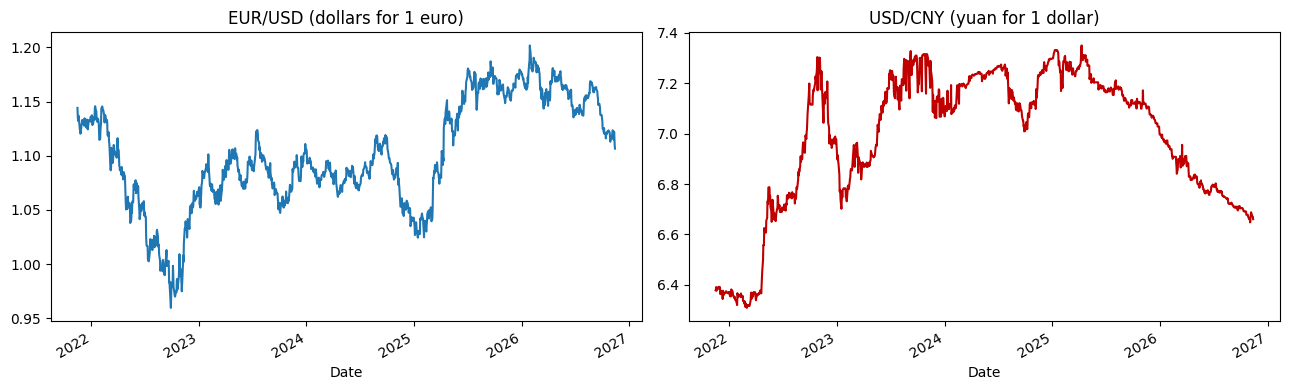

In [14]:
def download(ticker):
    data = yf.download(ticker, period="5y", progress=False, auto_adjust=True)
    return data["Close"].squeeze().dropna()

eurusd = download("EURUSD=X")   # dollars for 1 euro
usdcny = download("CNY=X")      # yuan for 1 dollar

spot_eur = float(eurusd.iloc[-1])
spot_cny = float(usdcny.iloc[-1])
print(f"EUR/USD today: {spot_eur:.4f}")
print(f"USD/CNY today: {spot_cny:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
eurusd.plot(ax=ax1, title="EUR/USD (dollars for 1 euro)")
usdcny.plot(ax=ax2, title="USD/CNY (yuan for 1 dollar)", color="#C00000")
plt.tight_layout(); plt.show()

### Volatility
Volatility measures how much a rate usually moves:

$$\sigma = \text{std}(r_t) \times \sqrt{252}$$

- $\sigma$: annual volatility
- $r_t = \ln(S_t / S_{t-1})$: daily return of the exchange rate
- $\text{std}$: standard deviation, measured over the last year
- $252$: number of trading days in a year

In [15]:
def annual_vol(series):
    returns = np.log(series / series.shift(1)).dropna()
    return float(returns[-252:].std() * np.sqrt(252))

vol_eur = annual_vol(eurusd)
vol_cny = annual_vol(usdcny)
print(f"EUR/USD volatility: {vol_eur:.2%}")
print(f"USD/CNY volatility: {vol_cny:.2%}  <- the yuan is managed by the PBoC, so it moves less")

EUR/USD volatility: 5.56%
USD/CNY volatility: 2.39%  <- the yuan is managed by the PBoC, so it moves less


---
# CASE 1 - French exporter receiving USD 10M (EUR/USD)

## 1.1 Forward
The bank fixes today the rate for 6 months. It includes the interest rate difference between the two currencies
(otherwise there would be a free arbitrage):

$$F = S \times e^{(r_{USD} - r_{EUR}) \times T}$$

- $F$: forward rate (dollars for 1 euro in 6 months)
- $S$: spot rate today
- $r_{USD}$, $r_{EUR}$: dollar and euro interest rates
- $T$: maturity in years (0.5)

In [16]:
fwd_eur = spot_eur * np.exp((r_usd - r_eur) * T)
eur_fwd_1 = amount_usd / fwd_eur
carry_1 = 1 - spot_eur / fwd_eur        # what the forward costs vs today's spot

print(f"Forward EUR/USD (6 months): {fwd_eur:.4f}")
print(f"Euros guaranteed: €{eur_fwd_1:,.0f}  ({carry_1:.2%} less than at today's spot)")

Forward EUR/USD (6 months): 1.1142
Euros guaranteed: €8,974,859  (0.69% less than at today's spot)


## 1.2 Option: EUR call
The company will sell dollars and **buy euros**. A **call on EUR** (which is the same thing as a **put on USD**) gives the right to buy euros at the strike K:
- EUR/USD ends **above** K → it uses the option and buys at K → protected
- EUR/USD ends **below** K → it converts at the better market rate → keeps the gain

Price with **Garman-Kohlhagen** (Black-Scholes for currencies). Strike K = forward rate.

$$C = S e^{-r_{EUR} T} N(d_1) - K e^{-r_{USD} T} N(d_2)$$
$$d_1 = \frac{\ln(S/K) + (r_{USD} - r_{EUR} + \sigma^2/2)\,T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$

- $C$: call price, in dollars for 1 euro of notional
- $K$: strike, the guaranteed rate
- $N(\cdot)$: probability under the standard normal distribution
- $\sigma$: volatility of EUR/USD
- the euro rate plays the role of a dividend: holding euros earns $r_{EUR}$

In [17]:
K1 = fwd_eur
d1 = (np.log(spot_eur / K1) + (r_usd - r_eur + vol_eur**2 / 2) * T) / (vol_eur * np.sqrt(T))
d2 = d1 - vol_eur * np.sqrt(T)
call = spot_eur * np.exp(-r_eur * T) * norm.cdf(d1) - K1 * np.exp(-r_usd * T) * norm.cdf(d2)  # USD per 1 EUR

premium_1 = call * (amount_usd / K1) / spot_eur    # total premium in euros
print(f"Strike: {K1:.4f} | premium: €{premium_1:,.0f} ({premium_1 / eur_fwd_1:.2%} of the amount)")

Strike: 1.1142 | premium: €138,885 (1.55% of the amount)


## 1.3 Simulation and results
I simulate 10,000 possible values of EUR/USD in 6 months:

$$S_T = S \times e^{(r_{USD} - r_{EUR} - \sigma^2/2)\,T + \sigma\sqrt{T}\,Z}$$

- $S_T$: simulated rate in 6 months
- $Z$: random number from a standard normal distribution (one per scenario)
- the average of $S_T$ equals the forward: the model does not try to predict the dollar

In [18]:
np.random.seed(42)
z = np.random.normal(0, 1, n_sims)
rate_1 = spot_eur * np.exp((r_usd - r_eur - vol_eur**2 / 2) * T + vol_eur * np.sqrt(T) * z)

case1 = pd.DataFrame({
    "No hedge": amount_usd / rate_1,
    "Forward":  np.full(n_sims, eur_fwd_1),
    "Option":   amount_usd / np.minimum(rate_1, K1) - premium_1,
})
summary1 = pd.DataFrame({
    "Average received (€)":     case1.mean(),
    "Bad case: 5% worst (€)":   case1.quantile(0.05),
    "Good case: 5% best (€)":   case1.quantile(0.95),
})
summary1.style.format("{:,.0f}")

,Average received (€),Bad case: 5% worst (€),Good case: 5% best (€)
No hedge,"8,989,519","8,420,531","9,585,024"
Forward,"8,974,859","8,974,859","8,974,859"
Option,"8,984,457","8,835,975","9,446,139"


---
# CASE 2 - Chinese exporter receiving USD 10M (USD/CNY)

Same method. USD/CNY = yuan for 1 dollar. If it **goes down** (weaker dollar), the exporter receives **fewer yuan**.

## 2.1 Forward
$$F = S \times e^{(r_{CNY} - r_{USD}) \times T}$$

- $F$: forward rate (yuan for 1 dollar in 6 months)
- $S$: spot rate today
- $r_{CNY}$, $r_{USD}$: yuan and dollar interest rates
- $T$: maturity in years (0.5)

Yuan rates are much lower than dollar rates, so the forward is **below** the spot: hedging is more expensive than for the French exporter.

In [19]:
fwd_cny = spot_cny * np.exp((r_cny - r_usd) * T)
cny_fwd_2 = amount_usd * fwd_cny
carry_2 = 1 - fwd_cny / spot_cny

print(f"Forward USD/CNY (6 months): {fwd_cny:.4f}")
print(f"Yuan guaranteed: ¥{cny_fwd_2:,.0f}  ({carry_2:.2%} less than at today's spot)")

Forward USD/CNY (6 months): 6.5785
Yuan guaranteed: ¥65,785,187  (1.23% less than at today's spot)


## 2.2 Option: USD put
The exporter will **sell dollars**. A **put on USD** gives the right to sell dollars at the strike K:
- USD/CNY ends **below** K → it uses the option and sells at K → protected
- USD/CNY ends **above** K → it converts at the better market rate → keeps the gain

Garman-Kohlhagen again, with the yuan as domestic currency and the dollar as foreign currency. Strike K = forward rate.

$$P = K e^{-r_{CNY} T} N(-d_2) - S e^{-r_{USD} T} N(-d_1)$$
$$d_1 = \frac{\ln(S/K) + (r_{CNY} - r_{USD} + \sigma^2/2)\,T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$

- $P$: put price, in yuan for 1 dollar of notional
- $K$: strike, the guaranteed rate
- $N(\cdot)$: probability under the standard normal distribution
- $\sigma$: volatility of USD/CNY

In [20]:
K2 = fwd_cny
d1 = (np.log(spot_cny / K2) + (r_cny - r_usd + vol_cny**2 / 2) * T) / (vol_cny * np.sqrt(T))
d2 = d1 - vol_cny * np.sqrt(T)
put = K2 * np.exp(-r_cny * T) * norm.cdf(-d2) - spot_cny * np.exp(-r_usd * T) * norm.cdf(-d1)  # CNY per 1 USD

premium_2 = put * amount_usd    # total premium in yuan
print(f"Strike: {K2:.4f} | premium: ¥{premium_2:,.0f} ({premium_2 / cny_fwd_2:.2%} of the amount)")

Strike: 6.5785 | premium: ¥440,490 (0.67% of the amount)


## 2.3 Simulation and results
Same simulation as in case 1, with the yuan and dollar rates and the USD/CNY volatility:

$$S_T = S \times e^{(r_{CNY} - r_{USD} - \sigma^2/2)\,T + \sigma\sqrt{T}\,Z}$$

In [21]:
np.random.seed(7)
z = np.random.normal(0, 1, n_sims)
rate_2 = spot_cny * np.exp((r_cny - r_usd - vol_cny**2 / 2) * T + vol_cny * np.sqrt(T) * z)

case2 = pd.DataFrame({
    "No hedge": amount_usd * rate_2,
    "Forward":  np.full(n_sims, cny_fwd_2),
    "Option":   amount_usd * np.maximum(rate_2, K2) - premium_2,   # the put floors the rate at K
})
summary2 = pd.DataFrame({
    "Average received (¥)":    case2.mean(),
    "Bad case: 5% worst (¥)":  case2.quantile(0.05),
    "Good case: 5% best (¥)":  case2.quantile(0.95),
})
summary2.style.format("{:,.0f}")

,Average received (¥),Bad case: 5% worst (¥),Good case: 5% best (¥)
No hedge,"65,774,952","63,955,299","67,588,834"
Forward,"65,785,187","65,785,187","65,785,187"
Option,"65,778,914","65,344,697","67,148,344"


---
# Side-by-side comparison
To compare two companies with different currencies, every result is expressed **in % of the amount at today's spot rate**.

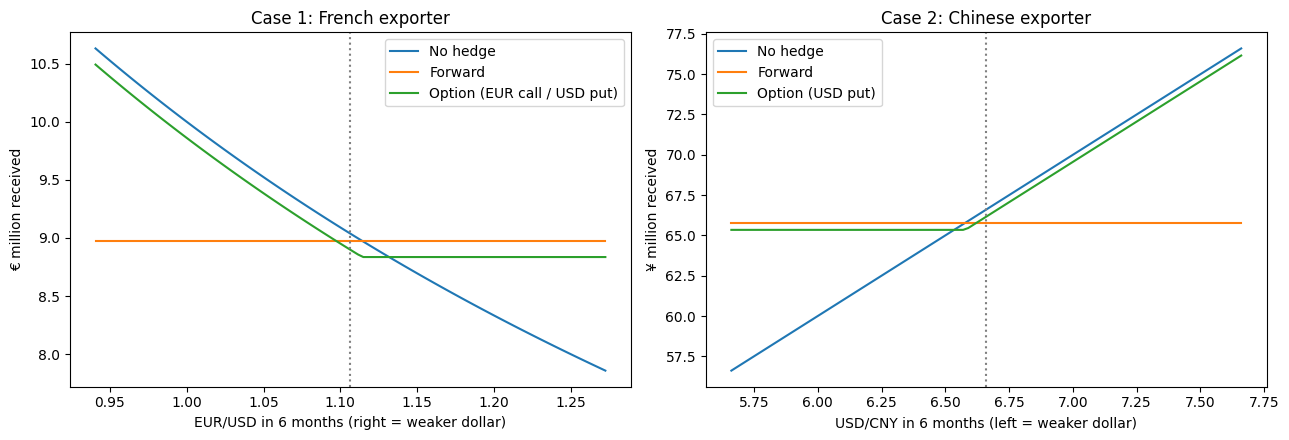

,Case 1: French exporter (EUR/USD),Case 2: Chinese exporter (USD/CNY)
Volatility,5.56%,2.39%
Cost of the forward vs spot,0.69%,1.23%
Option premium,1.54%,0.66%
Unhedged risk (average - 5% worst),6.30%,2.73%


In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

r1 = np.linspace(spot_eur * 0.85, spot_eur * 1.15, 100)
ax1.plot(r1, amount_usd / r1 / 1e6, label="No hedge")
ax1.plot(r1, np.full(100, eur_fwd_1) / 1e6, label="Forward")
ax1.plot(r1, (amount_usd / np.minimum(r1, K1) - premium_1) / 1e6, label="Option (EUR call / USD put)")
ax1.axvline(spot_eur, color="grey", linestyle=":")
ax1.set(title="Case 1: French exporter", xlabel="EUR/USD in 6 months (right = weaker dollar)", ylabel="€ million received")
ax1.legend()

r2 = np.linspace(spot_cny * 0.85, spot_cny * 1.15, 100)
ax2.plot(r2, amount_usd * r2 / 1e6, label="No hedge")
ax2.plot(r2, np.full(100, cny_fwd_2) / 1e6, label="Forward")
ax2.plot(r2, (amount_usd * np.maximum(r2, K2) - premium_2) / 1e6, label="Option (USD put)")
ax2.axvline(spot_cny, color="grey", linestyle=":")
ax2.set(title="Case 2: Chinese exporter", xlabel="USD/CNY in 6 months (left = weaker dollar)", ylabel="¥ million received")
ax2.legend()
plt.tight_layout(); plt.show()

base_1 = amount_usd / spot_eur      # value at today's spot, in EUR
base_2 = amount_usd * spot_cny      # value at today's spot, in CNY
comparison = pd.DataFrame({
    "Case 1: French exporter (EUR/USD)": [
        f"{vol_eur:.2%}", f"{carry_1:.2%}", f"{premium_1 / base_1:.2%}",
        f"{(case1['No hedge'].mean() - case1['No hedge'].quantile(0.05)) / base_1:.2%}"],
    "Case 2: Chinese exporter (USD/CNY)": [
        f"{vol_cny:.2%}", f"{carry_2:.2%}", f"{premium_2 / base_2:.2%}",
        f"{(case2['No hedge'].mean() - case2['No hedge'].quantile(0.05)) / base_2:.2%}"],
}, index=["Volatility", "Cost of the forward vs spot", "Option premium", "Unhedged risk (average - 5% worst)"])
comparison

---
# Conclusions

**Same problem, same tools.** Both exporters receive dollars and fear a weaker dollar. Both can fix the rate with a forward,
or buy a **put on USD** (for the French exporter it is quoted as a EUR call, but it is the same protection).

**What changes is the market:**
- **Risk:** USD/CNY is much less volatile than EUR/USD because the PBoC manages the yuan (daily fixing, ±2% band).
  An unhedged Chinese exporter takes much less risk than a French one.
- **Cost of the forward:** it depends on the interest rate gap. The gap is larger between the dollar and the yuan (≈ 2.5 points)
  than between the dollar and the euro (≈ 1.4 points), so the forward costs the Chinese exporter more.
- **Consequence:** for the Chinese exporter, the forward costs more while the risk is lower. This helps explain why many Chinese exporters
  hedge only a small part of their dollar receivables, and why low volatility makes options relatively cheap for them.

**Limits of the model for the yuan:**
- **Policy jumps:** the yuan can jump after a central bank decision (e.g. the August 2015 devaluation); a smooth lognormal model underestimates this risk.
- **CNY vs CNH:** an exporter hedging offshore (CNH) while being paid onshore (CNY) keeps a small gap between the two (*basis risk*).
- **General:** realised instead of implied volatility, policy rates as proxies for money-market rates, no bank margin (bid/ask).

**Next steps:** zero-cost collar, stress tests, implied volatility from the market.